# Euro FX Futures: When Does Rolling Happen?
**FINM 37000 | Gonzalo Romero | Evidence for the method decision (#12)**

## Question
`roll_volume_exploration.ipynb` measures the deferred contract's share of outright volume. A position can also be rolled in one trade through the exchange-listed calendar spread, which CME reports as trades in the spread instrument rather than in the two outright contracts. Does spread volume confirm that rolling happens in the proposed roll window (the last full Monday–Friday week before expiry)?

## Method
For the same eight rolls (December 2024 to September 2026), pull daily `ohlcv-1d` bars for the front, the deferred and the listed spread, plus CME cleared volume (`statistics`) for the front. Rolls and windows come from `euro_roll.expiries` and `euro_roll.windows`; requests go through `euro_roll.download`. Data runs from the control window's baseline Friday to expiry. Volume only; no spread prices are examined.

To rerun, set `DATABENTO_API_KEY` in the environment and review the cost estimate before downloading.

## Data

In [1]:
import sys
from datetime import date, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
from euro_roll.client import get_client
from euro_roll.download import fetch, request_params, spread_symbol
from euro_roll.expiries import roll_calendar
from euro_roll.windows import select_windows

client = get_client()

In [2]:
# The eight recent rolls, reported as exploratory in the README.
FIRST, LAST = date(2024, 12, 1), date(2026, 9, 30)
rolls = select_windows(p for p in roll_calendar(2024, 2026) if FIRST <= p[2] <= LAST)

pd.DataFrame([
    {"front": r.front, "deferred": r.deferred, "expiry": r.expiry,
     "control_start": r.control.start, "roll_start": r.roll.start,
     "roll_end": r.roll.end}
    for r in rolls
])

,front,deferred,expiry,control_start,roll_start,roll_end
0,6EZ4,6EH5,2024-12-16,2024-11-11,2024-12-09,2024-12-13
1,6EH5,6EM5,2025-03-17,2025-02-10,2025-03-10,2025-03-14
2,6EM5,6EU5,2025-06-16,2025-05-12,2025-06-09,2025-06-13
3,6EU5,6EZ5,2025-09-15,2025-08-11,2025-09-08,2025-09-12
4,6EZ5,6EH6,2025-12-15,2025-11-10,2025-12-08,2025-12-12
5,6EH6,6EM6,2026-03-16,2026-02-09,2026-03-09,2026-03-13
6,6EM6,6EU6,2026-06-15,2026-05-11,2026-06-08,2026-06-12
7,6EU6,6EZ6,2026-09-14,2026-08-10,2026-09-07,2026-09-11


In [3]:
def data_range(r):
    """Control baseline Friday through expiry day (end is exclusive)."""
    return r.control.baseline, r.expiry + timedelta(days=1)


def bar_symbols(r):
    return [r.front, r.deferred, spread_symbol(r.front, r.deferred)]


def cost(schema, symbols, r):
    return client.metadata.get_cost(**request_params(schema, symbols, *data_range(r)))


total = sum(
    cost("ohlcv-1d", bar_symbols(r), r) + cost("statistics", r.front, r) for r in rolls
)
print(f"Estimated cost: ${total:.4f}")

Estimated cost: $0.0000


In [4]:
CLEARED_VOLUME = 6  # databento StatType.CLEARED_VOLUME


def session_day(ts):
    """UTC bar date, with the Sunday evening bar counted in Monday's session."""
    d = ts.date()
    return d + timedelta(days=1) if d.weekday() == 6 else d


def window_label(r, d):
    windows = {"roll": r.roll, "week before": r.roll.shifted(-1), "control": r.control}
    for name, w in windows.items():
        if w.start <= d <= w.end:
            return name
    return ""


def daily_table(r):
    bars = fetch("ohlcv-1d", bar_symbols(r), *data_range(r), client)
    bars["day"] = [session_day(t) for t in bars.index]
    vol = bars.pivot_table(index="day", columns="symbol", values="volume",
                           aggfunc="sum")

    stats = fetch("statistics", r.front, *data_range(r), client)
    stats = stats[stats["stat_type"] == CLEARED_VOLUME].sort_index()
    stats["day"] = pd.to_datetime(stats["ts_ref"], utc=True).dt.date
    cleared = stats.groupby("day")["quantity"].last()

    table = pd.DataFrame({
        "front": vol[r.front],
        "deferred": vol[r.deferred],
        "spread": vol[spread_symbol(r.front, r.deferred)],
        "front_cleared": cleared.reindex(vol.index),
    })
    table["window"] = [window_label(r, d) for d in table.index]
    return table


tables = {r.front: daily_table(r) for r in rolls}

## Where Spread Volume Falls

In [5]:
def spread_share(t, mask):
    return t.loc[mask, "spread"].sum() / t["spread"].sum()


def summarize(r, t):
    in_roll = t["window"] == "roll"
    roll = t[in_roll].sum(numeric_only=True)
    peak = t["spread"].idxmax()
    below = (t.loc[in_roll, "front"] < t.loc[in_roll, "spread"]).sum()
    return {
        "roll": f"{r.front}->{r.deferred}",
        "week_before": spread_share(t, t["window"] == "week before"),
        "roll_week": spread_share(t, in_roll),
        "roll_mon_thu": spread_share(t, in_roll & (t.index != r.roll.end)),
        "control_week": spread_share(t, t["window"] == "control"),
        "peak_day": f"{peak:%a %Y-%m-%d}",
        # Bars that included this spread's front-leg fills could never be
        # smaller than the spread's own volume.
        "front_below_spread": f"{below} of {in_roll.sum()} days",
        # Weekly sums, so holiday trades booked to the next trade date still match.
        "cleared_gap_to_spread":
            (roll["front_cleared"] - roll["front"]) / roll["spread"],
        "spread_to_cleared": roll["spread"] / roll["front_cleared"],
    }


summary = pd.DataFrame([summarize(r, tables[r.front]) for r in rolls])
summary.round(2)

,roll,week_before,roll_week,roll_mon_thu,control_week,peak_day,front_below_spread,cleared_gap_to_spread,spread_to_cleared
0,6EZ4->6EH5,0.12,0.83,0.77,0.01,Wed 2024-12-11,3 of 5 days,1.08,0.48
1,6EH5->6EM5,0.15,0.80,0.72,0.01,Wed 2025-03-12,2 of 5 days,1.15,0.43
2,6EM5->6EU5,0.10,0.86,0.75,0.00,Wed 2025-06-11,4 of 5 days,1.07,0.62
3,6EU5->6EZ5,0.12,0.83,0.75,0.01,Wed 2025-09-10,4 of 5 days,1.12,0.60
4,6EZ5->6EH6,0.11,0.84,0.79,0.01,Wed 2025-12-10,4 of 5 days,1.14,0.59
5,6EH6->6EM6,0.17,0.80,0.75,0.01,Wed 2026-03-11,4 of 5 days,1.12,0.52
6,6EM6->6EU6,0.07,0.87,0.82,0.00,Wed 2026-06-10,4 of 5 days,1.13,0.56
7,6EU6->6EZ6,0.13,0.82,0.76,0.00,Wed 2026-09-09,4 of 5 days,1.21,0.56


In [6]:
# Most recent roll: the week before, the roll week and expiry. Monday 2026-09-07
# is Labor Day; CME books its trades into Tuesday's cleared volume.
last = rolls[-1]
tables[last.front].loc[last.roll.start - timedelta(days=7):]

,front,deferred,spread,front_cleared,window
day,,,,,
2026-08-31,133204,3201,15374,155434.0,week before
2026-09-01,117649,3010,4131,138427.0,week before
2026-09-02,142626,4088,37035,196388.0,week before
2026-09-03,156009,7795,36285,206967.0,week before
2026-09-04,131740,7619,52184,187997.0,week before
2026-09-07,63165,7476,28512,0.0,roll
2026-09-08,142565,18393,215075,480919.0,roll
2026-09-09,158180,29885,337394,627778.0,roll
2026-09-10,124694,59149,249959,395102.0,roll


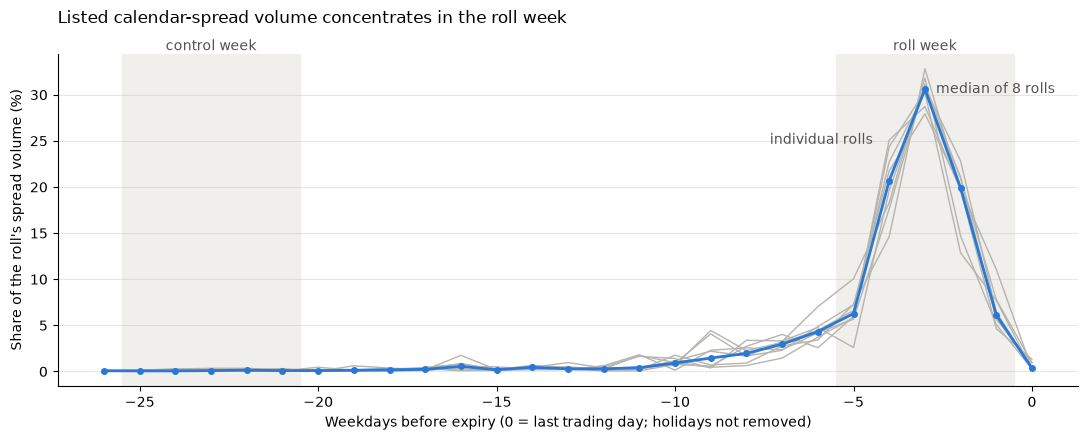

In [7]:
BLUE, GRAY, BAND, INK = "#2a78d6", "#b5b4ae", "#f0efec", "#52514e"

fig, ax = plt.subplots(figsize=(11, 4.5))
for name, start, end in [("control week", -25, -21), ("roll week", -5, -1)]:
    ax.axvspan(start - 0.5, end + 0.5, color=BAND, zorder=0)
    ax.text((start + end) / 2, 1.0, name, transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", color=INK)

shares = []
for r in rolls:
    t = tables[r.front]
    days = t.index.values.astype("datetime64[D]")
    offset = -np.busday_count(days, np.datetime64(r.expiry))
    share = pd.Series(100 * t["spread"].values / t["spread"].sum(), index=offset)
    shares.append(share)
    ax.plot(share.index, share.values, color=GRAY, linewidth=1)

median = pd.concat(shares, axis=1).median(axis=1).sort_index()
ax.plot(median.index, median.values, color=BLUE, linewidth=2, marker="o", markersize=4)
ax.annotate("median of 8 rolls", (median.idxmax(), median.max()), xytext=(8, 0),
            textcoords="offset points", color=INK, va="center")
ax.annotate("individual rolls", (-4, max(s.get(-4, 0) for s in shares)),
            xytext=(-12, 0), textcoords="offset points", color=INK,
            ha="right", va="center")

ax.set_xlabel("Weekdays before expiry (0 = last trading day; holidays not removed)")
ax.set_ylabel("Share of the roll's spread volume (%)")
ax.set_title("Listed calendar-spread volume concentrates in the roll week",
             loc="left", pad=22)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Finding
In all eight rolls, 80–87% of the listed spread's volume over the roughly five weeks before expiry trades in the proposed roll window (the Monday–Friday week before expiry). The week before carries 7–17%, and the control week four weeks earlier 0–1%. The roll week's Wednesday is the busiest day every time. Monday to Thursday alone carry 72–82%, so at least that much trades before the Friday 10:00 snapshot that ends the window. The window captures most of the roll, though some rolling starts the week before.

Outright daily bars leave out this spread's leg fills. On two to four of the five roll-week days in every roll, the front's bar volume is smaller than the spread's own volume, which could not happen if the bars counted the spread's front leg. In the roll week, spread volume is 43–62% of the front's cleared volume, and cleared volume exceeds the front's bars by 1.07–1.21 times the spread volume. The excess over 1 is likely other spreads that include the front, and trades away from Globex.

So the outright volume share in `roll_volume_exploration.ipynb`, which crosses 50% on Friday, shows where outright trading moves after positions have rolled. Counting spread legs would not move that crossover, because each spread trade adds the same amount to both contracts. Spread volume peaks two days earlier.

**Limits.** These are the eight recent rolls, the same exploratory sample that motivated the project. The result supports keeping the proposed window rule; it should not be used to narrow the window. Dates are UTC daily bars, with the Sunday evening bar counted in Monday; the Wednesday peak was also confirmed on CME trade dates (cleared volume) for the September 2026 roll only. Monday 2026-09-07 is Labor Day, inside that roll week; CME books its trades into Tuesday, so the cleared comparison uses weekly sums. Rolling may have looked different in 2010–2024. Databento flagged degraded data on 2025-11-28, 2026-03-15, 2026-03-16, 2026-05-24 and 2026-08-29; none falls in a roll or control week.